In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)
import warnings
warnings.filterwarnings("ignore")
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.model_selection import GridSearchCV

In [2]:
df_bank = pd.read_csv('Bank+Customer+Churn/Bank_Churn.csv')

# View the first 5 rows
df_bank.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df_bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 1015.8+ KB


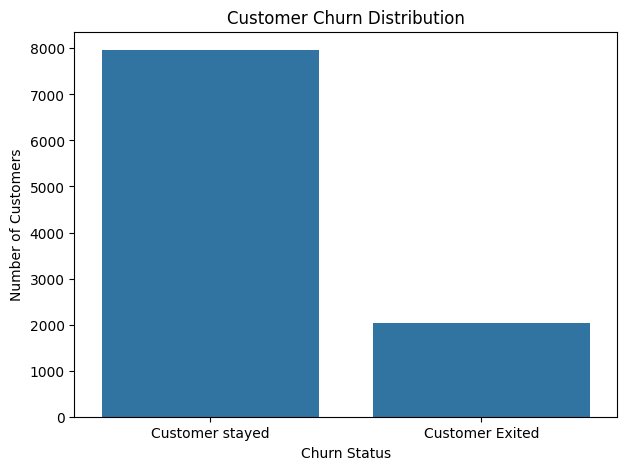

In [4]:
# Customer Churn Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df_bank, x='Exited')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['Customer stayed', 'Customer Exited'])

plt.show()

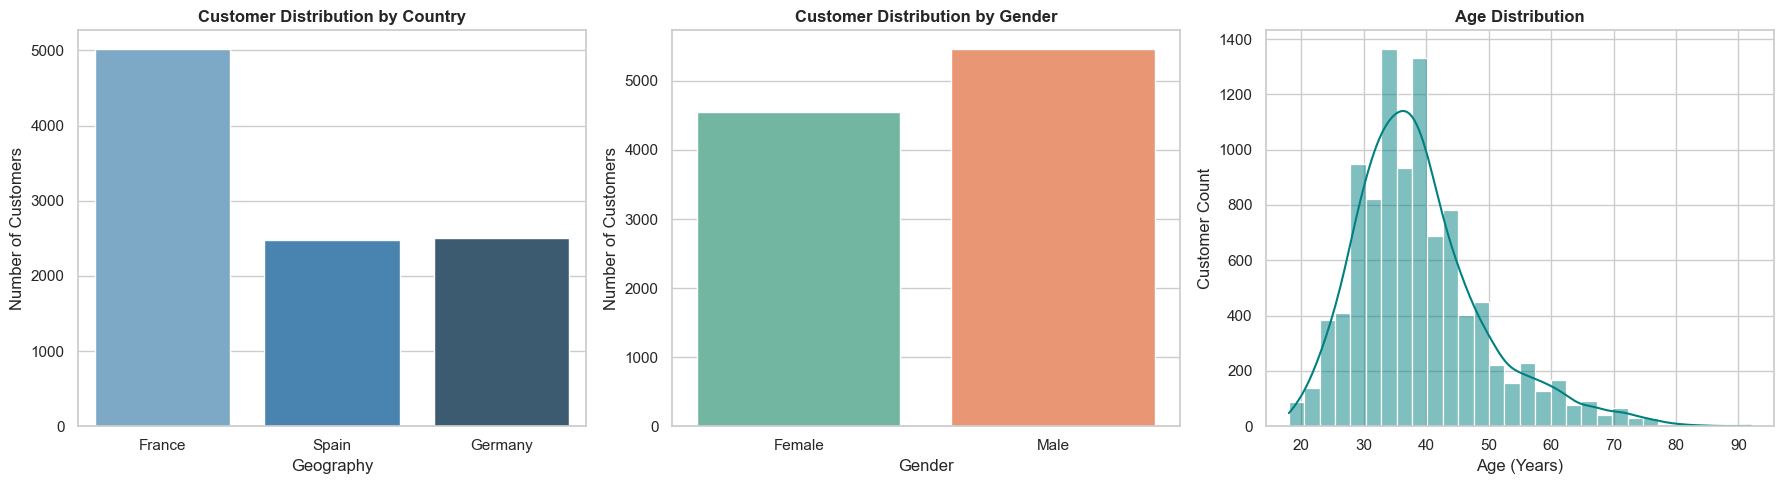


Demographics Summary

Geographic Breakdown (%):
Geography
France     50.14
Germany    25.09
Spain      24.77
Name: proportion, dtype: float64

Gender Breakdown (%):
Gender
Male      54.57
Female    45.43
Name: proportion, dtype: float64

Average Age: 38.9 years (Median: 37)


In [5]:
# Set visual style
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Geographic Distribution
sns.countplot(data=df_bank, x='Geography', ax=axes[0], palette='Blues_d')
axes[0].set_title('Customer Distribution by Country', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Customers')

# Gender Distribution
sns.countplot(data=df_bank, x='Gender', ax=axes[1], palette='Set2')
axes[1].set_title('Customer Distribution by Gender', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Number of Customers')

# Age Distribution
sns.histplot(data=df_bank, x='Age', kde=True, bins=30, ax=axes[2], color='teal')
axes[2].set_title('Age Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Age (Years)')
axes[2].set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

print("\nDemographics Summary")
print("\nGeographic Breakdown (%):")
print(df_bank['Geography'].value_counts(normalize=True) * 100)
print("\nGender Breakdown (%):")
print(df_bank['Gender'].value_counts(normalize=True) * 100)
print(f"\nAverage Age: {df_bank['Age'].mean():.1f} years (Median: {df_bank['Age'].median():.0f})")

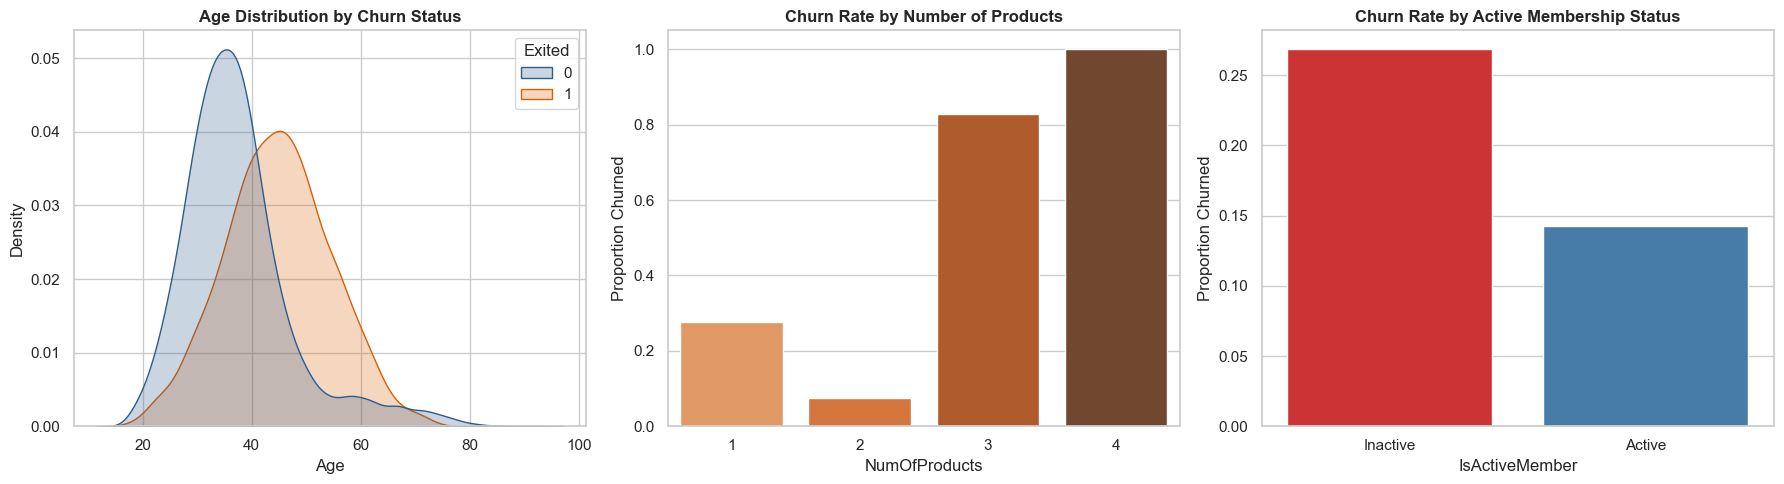


Attribute Means: Retained vs. Churned
                Age   Balance  NumOfProducts  IsActiveMember  CreditScore
Retained (0)  37.41  72745.30           1.54            0.55       651.85
Churned (1)   44.84  91108.54           1.48            0.36       645.35


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Age density overlay by churn status
sns.kdeplot(data=df_bank, x='Age', hue='Exited', common_norm=False, fill=True, ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title('Age Distribution by Churn Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age')

# Churn rate by Number of Products
sns.barplot(data=df_bank, x='NumOfProducts', y='Exited', ax=axes[1], palette='Oranges_d', ci=None)
axes[1].set_title('Churn Rate by Number of Products', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Proportion Churned')

# Churn rate by Member Activity Status
sns.barplot(data=df_bank, x='IsActiveMember', y='Exited', ax=axes[2], palette='Set1', ci=None)
axes[2].set_title('Churn Rate by Active Membership Status', fontsize=12, fontweight='bold')
axes[2].set_xticklabels(['Inactive', 'Active'])
axes[2].set_ylabel('Proportion Churned')

plt.tight_layout()
plt.show()

# Quantitative comparison of attributes between churners and non-churners
print("\nAttribute Means: Retained vs. Churned")
comparison = df_bank.groupby('Exited')[['Age', 'Balance', 'NumOfProducts', 'IsActiveMember', 'CreditScore']].mean()
comparison.index = ['Retained (0)', 'Churned (1)']
print(comparison.round(2))

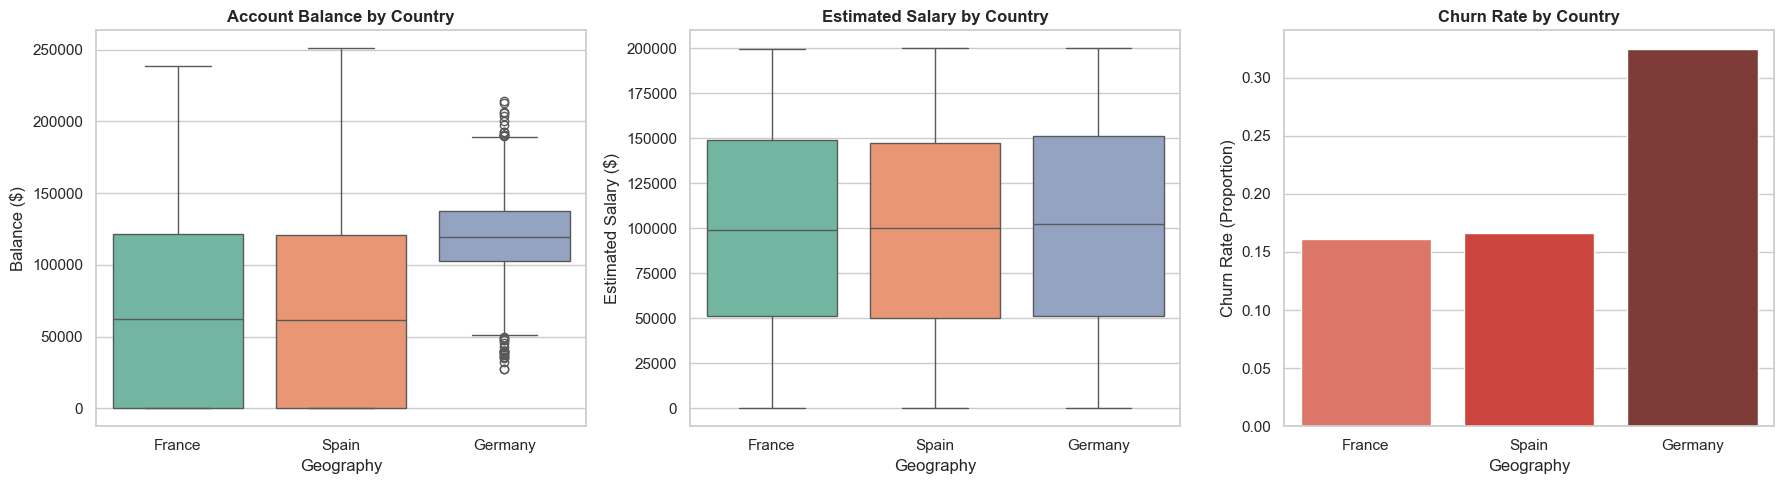


Geographic Behavior Summary
           Avg_Balance  Zero_Balance_Pct  Avg_Salary  Churn_Rate
Geography                                                       
France        62092.64             48.22    99899.18       16.15
Germany      119730.12              0.00   101113.44       32.44
Spain         61818.15             48.41    99440.57       16.67


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Account Balance by Country
sns.boxplot(data=df_bank, x='Geography', y='Balance', ax=axes[0], palette='Set2')
axes[0].set_title('Account Balance by Country', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Balance ($)')

# Estimated Salary by Country
sns.boxplot(data=df_bank, x='Geography', y='EstimatedSalary', ax=axes[1], palette='Set2')
axes[1].set_title('Estimated Salary by Country', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Estimated Salary ($)')

# Overall Churn Rate by Country
sns.barplot(data=df_bank, x='Geography', y='Exited', ax=axes[2], palette='Reds_d', ci=None)
axes[2].set_title('Churn Rate by Country', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Churn Rate (Proportion)')

plt.tight_layout()
plt.show()

# Summary statistics grouped by Geography
print("\nGeographic Behavior Summary")
geo_summary = df_bank.groupby('Geography').agg(
    Avg_Balance=('Balance', 'mean'),
    Zero_Balance_Pct=('Balance', lambda x: (x == 0).mean() * 100),
    Avg_Salary=('EstimatedSalary', 'mean'),
    Churn_Rate=('Exited', lambda x: x.mean() * 100)
)
print(geo_summary.round(2))

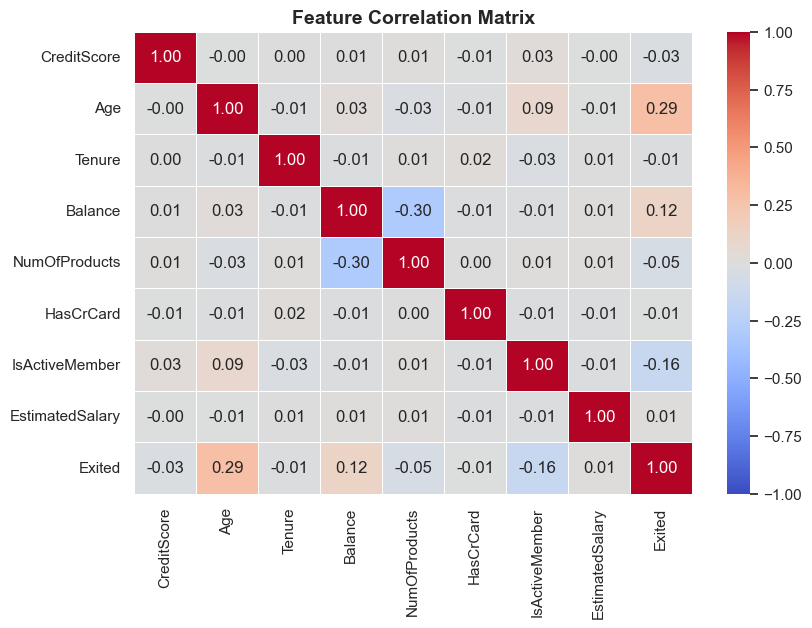

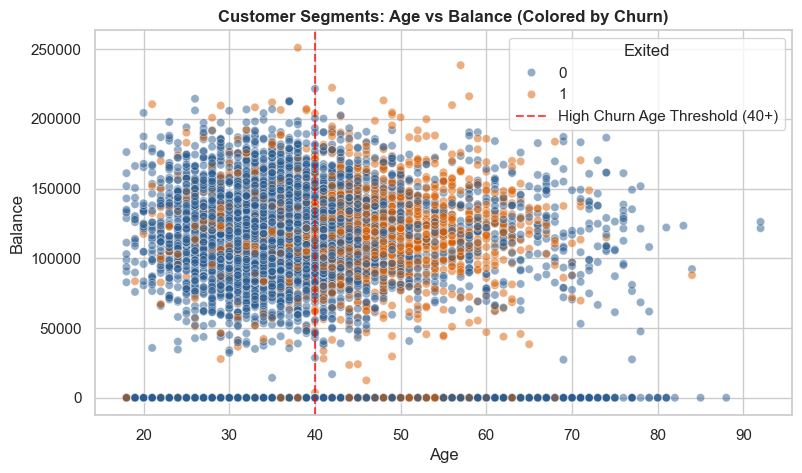

Identified Heuristic Segments & Churn Rates
                       Customer_Count  Churn_Rate
Segment                                          
Inactive German                   819       22.22
Low Risk                         6624        8.56
Multi-Product At Risk             326       85.89
Older Single-Product             2231       45.18


In [8]:
# Feature Correlation Matrix Heatmap
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
corr_matrix = df_bank[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()

# Segment Analysis: Balance vs Age colored by Churn Status
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_bank, x='Age', y='Balance', hue='Exited', alpha=0.5, palette=['#2b5c8f', '#d95f02'])
plt.title('Customer Segments: Age vs Balance (Colored by Churn)', fontsize=12, fontweight='bold')
plt.axvline(x=40, color='red', linestyle='--', alpha=0.7, label='High Churn Age Threshold (40+)')
plt.legend(title='Exited')
plt.show()

# Segment Profiling Example
df_bank['Segment'] = 'Low Risk'
df_bank.loc[(df_bank['Geography'] == 'Germany') & (df_bank['IsActiveMember'] == 0), 'Segment'] = 'Inactive German'
df_bank.loc[(df_bank['Age'] >= 40) & (df_bank['NumOfProducts'] == 1), 'Segment'] = 'Older Single-Product'
df_bank.loc[df_bank['NumOfProducts'] >= 3, 'Segment'] = 'Multi-Product At Risk'

print("Identified Heuristic Segments & Churn Rates")
segment_profile = df_bank.groupby('Segment').agg(
    Customer_Count=('Exited', 'count'),
    Churn_Rate=('Exited', lambda x: x.mean() * 100)
)
print(segment_profile.round(2))

In [9]:
# Drop the customer id and surname
df_bank =df_bank.drop(columns=['CustomerId','Surname'])

In [10]:
# Check head
df_bank.head(5)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Segment
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Older Single-Product
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Older Single-Product
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Multi-Product At Risk
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Low Risk
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Older Single-Product


In [11]:
# Map Male to 1 and Female to 0
df_bank['Gender'] = df_bank['Gender'].map({'Male': 1, 'Female': 0})

In [12]:
# Convert Geography into binary dummy columns
df_bank = pd.get_dummies(df_bank, columns=['Geography'], drop_first=True, dtype=int)

# Check the new columns
df_bank.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Segment,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,Older Single-Product,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,Older Single-Product,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,Multi-Product At Risk,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,Low Risk,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,Older Single-Product,0,1


In [13]:
# Define Features (X) and Target (y)
X = df_bank.drop(columns=['Exited', 'Segment'], errors='ignore')
y = df_bank['Exited']

In [14]:
# Train-Test Split 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [15]:
# Use Standard Scaler to scale your data
scaler = StandardScaler()

X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [16]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=2, min_samples_split=5,
                       n_estimators=200, n_jobs=-1, random_state=42)

In [17]:
y_pred = rf_model.predict(X_test_scaled)
y_proba = rf_model.predict_proba(X_test_scaled)[:, 1]

Classification Report
              precision    recall  f1-score   support

Retained (0)       0.91      0.89      0.90      1593
 Churned (1)       0.60      0.67      0.63       407

    accuracy                           0.84      2000
   macro avg       0.76      0.78      0.77      2000
weighted avg       0.85      0.84      0.85      2000

ROC-AUC Score: 0.8636


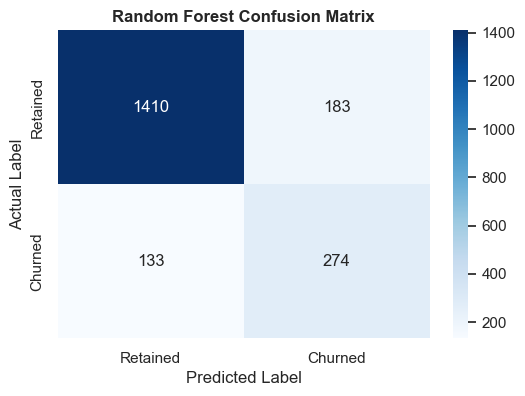

In [18]:
print("Classification Report")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot a Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Retained', 'Churned'], 
            yticklabels=['Retained', 'Churned'])
plt.title('Random Forest Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

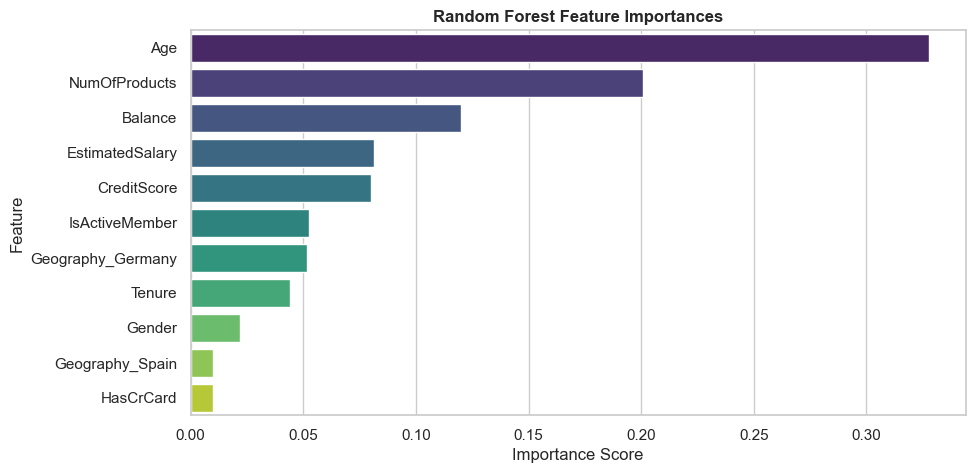

In [19]:
# Create a DataFrame for feature importances
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Random Forest Feature Importances', fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

In [20]:
cb_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0
)

cb_model.fit(X_train_scaled, y_train)

CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=300, learning_rate=0.05, random_state=42, verbose=0)

In [21]:
y_pred = cb_model.predict(X_test_scaled)
y_proba = cb_model.predict_proba(X_test_scaled)[:, 1]

CatBoost Classification Report
              precision    recall  f1-score   support

Retained (0)       0.93      0.83      0.88      1593
 Churned (1)       0.53      0.74      0.62       407

    accuracy                           0.81      2000
   macro avg       0.73      0.79      0.75      2000
weighted avg       0.85      0.81      0.82      2000

ROC-AUC Score: 0.8666


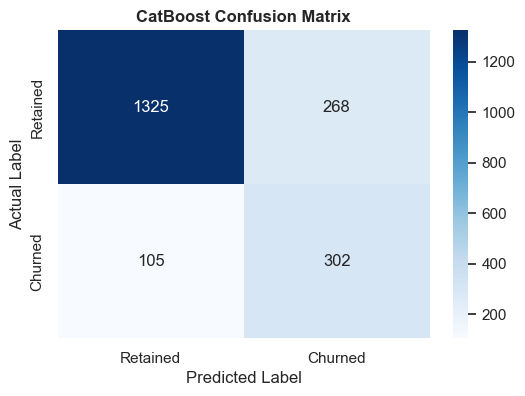

In [22]:
print("CatBoost Classification Report")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Retained', 'Churned'], 
            yticklabels=['Retained', 'Churned'])
plt.title('CatBoost Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

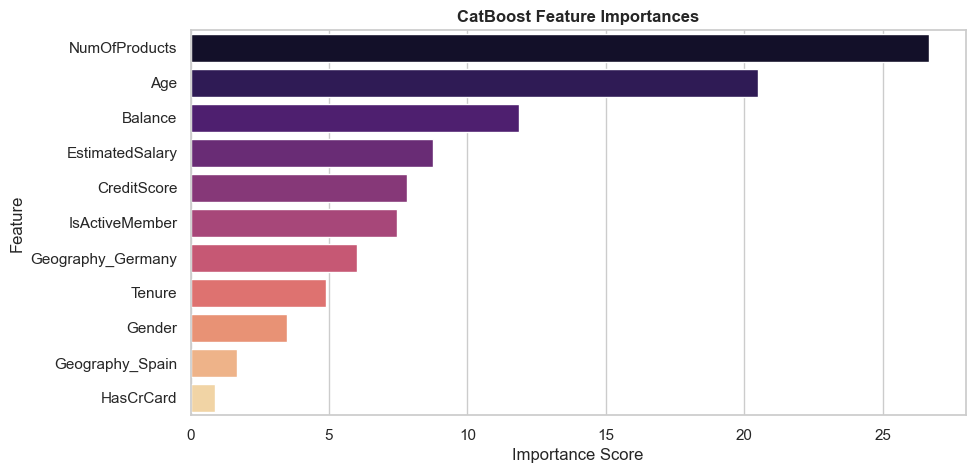

In [23]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': cb_model.get_feature_importance()
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='magma')
plt.title('CatBoost Feature Importances', fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

In [24]:
# Tune my model 
cb_base = CatBoostClassifier(
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0
)

In [25]:
param_grid = {
    'depth': [4, 6, 8],
    'learning_rate': [0.01, 0.03, 0.1],
    'iterations': [200, 300, 500],
    'l2_leaf_reg': [1, 3, 5]
}

In [26]:
grid_search = GridSearchCV(
    estimator=cb_base,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print(f"Best ROC-AUC Score: {grid_search.best_score_:.4f}")
print("Best Hyperparameters:")
print(grid_search.best_params_)

best_cb = grid_search.best_estimator_

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best ROC-AUC Score: 0.8702
Best Hyperparameters:
{'depth': 4, 'iterations': 200, 'l2_leaf_reg': 5, 'learning_rate': 0.1}


In [27]:
# Instantiate the final model with best parameters
best_cb_model = CatBoostClassifier(
    depth=4,
    iterations=200,
    l2_leaf_reg=5,
    learning_rate=0.1,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0
)

# 
best_cb_model.fit(X_train_scaled, y_train)

CatBoostClassifier(auto_class_weights='Balanced', depth=4, iterations=200, l2_leaf_reg=5, learning_rate=0.1, random_state=42, verbose=0)

In [28]:
y_pred = best_cb_model.predict(X_test)
y_proba = best_cb_model.predict_proba(X_test)[:, 1]

In [29]:
print("Final Tuned CatBoost Performance")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))
test_auc = roc_auc_score(y_test, y_proba)
print(f"Test Set ROC-AUC Score: {test_auc:.4f}")

Final Tuned CatBoost Performance
              precision    recall  f1-score   support

Retained (0)       0.80      0.80      0.80      1593
 Churned (1)       0.22      0.22      0.22       407

    accuracy                           0.68      2000
   macro avg       0.51      0.51      0.51      2000
weighted avg       0.68      0.68      0.68      2000

Test Set ROC-AUC Score: 0.3857


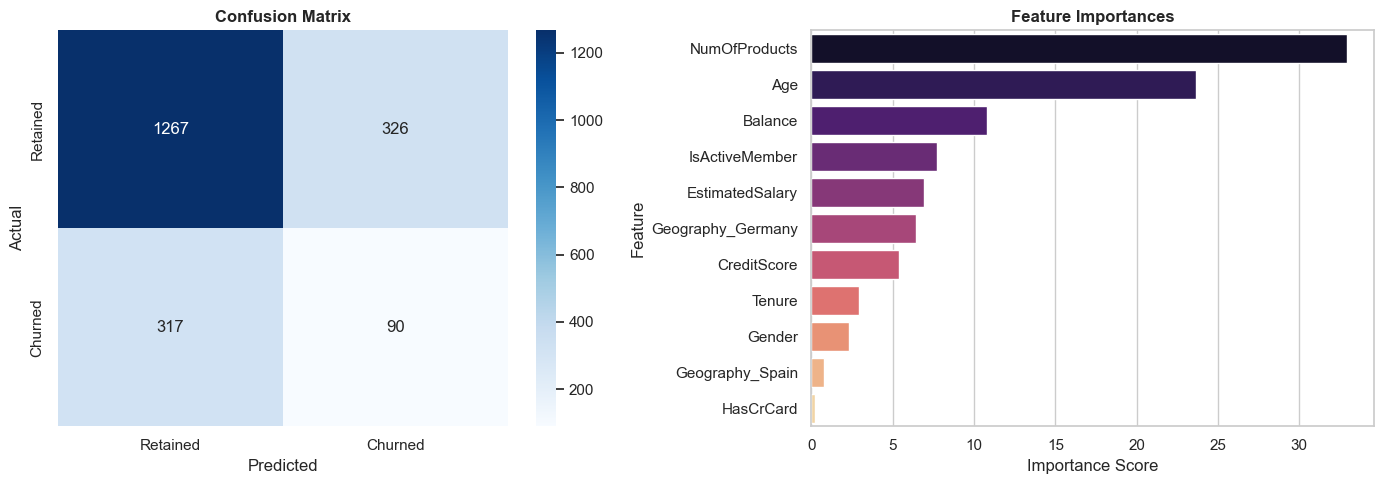

In [30]:
#  Visualizations: Confusion Matrix & Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained', 'Churned'], 
            yticklabels=['Retained', 'Churned'])
axes[0].set_title('Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')


importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_cb_model.get_feature_importance()
}).sort_values(by='Importance', ascending=False)

sns.barplot(data=importance_df, x='Importance', y='Feature', ax=axes[1], palette='magma')
axes[1].set_title('Feature Importances', fontweight='bold')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()


In [31]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

print("CV AUC:", grid_search.best_score_)

# Check the model against the same data it trained on, then the test set
print("Train AUC:", roc_auc_score(y_train, best_cb.predict_proba(X_train)[:, 1]))
print("Test AUC: ", roc_auc_score(y_test,  best_cb.predict_proba(X_test)[:, 1]))

# Alignment checks
print(list(X_train.columns) == list(X_test.columns))
print(type(X_train), type(X_test))
print(y_train.mean(), y_test.mean())   # both should be about 0.20

# Predict directly, using column 1 for the churn probability
y_pred = best_cb.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

CV AUC: 0.8702372123932159
Train AUC: 0.36279059240496564
Test AUC:  0.3856822924619535
True
<class 'pandas.core.frame.DataFrame'> <class 'pandas.core.frame.DataFrame'>
0.20375 0.2035
              precision    recall  f1-score   support

           0       0.80      0.80      0.80      1593
           1       0.22      0.22      0.22       407

    accuracy                           0.68      2000
   macro avg       0.51      0.51      0.51      2000
weighted avg       0.68      0.68      0.68      2000

[[1267  326]
 [ 317   90]]


In [32]:
log_reg = LogisticRegression(
    class_weight='balanced', 
    max_iter=1000,
    random_state=42
)

log_reg.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [37]:
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Classification Report")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))
test_auc = roc_auc_score(y_test, y_proba)
print(f"Test Set ROC-AUC Score: {test_auc:.4f}\n")

Logistic Regression Classification Report
              precision    recall  f1-score   support

Retained (0)       0.90      0.72      0.80      1593
 Churned (1)       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

Test Set ROC-AUC Score: 0.7771



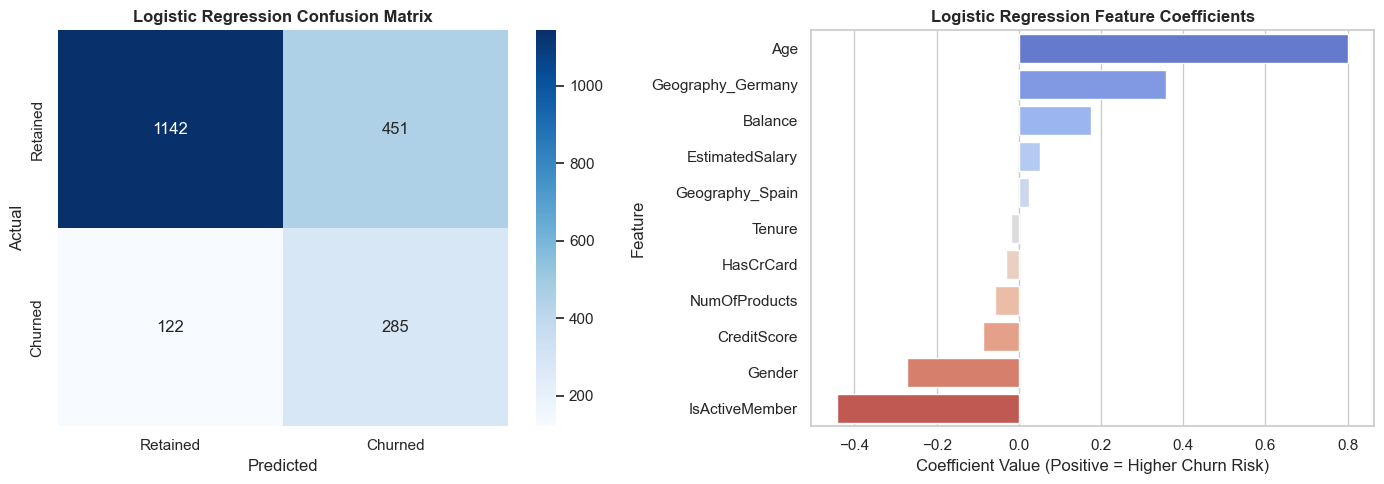

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained', 'Churned'], 
            yticklabels=['Retained', 'Churned'])
axes[0].set_title('Logistic Regression Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

sns.barplot(data=coef_df, x='Coefficient', y='Feature', ax=axes[1], palette='coolwarm')
axes[1].set_title('Logistic Regression Feature Coefficients', fontweight='bold')
axes[1].set_xlabel('Coefficient Value (Positive = Higher Churn Risk)')

plt.tight_layout()
plt.show()

In [38]:
X.columns

Index(['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany',
       'Geography_Spain'],
      dtype='object')

In [41]:
import joblib
joblib.dump(rf_model, "random_forest_model.pkl")
joblib.dump(scaler, "churn_scaler.pkl")

['churn_scaler.pkl']